# Reading sleep and wake from frontal-cortex spikes

**PSYC 40 final project · Luca Gandrud · Dartmouth, November 2026**

Code and results: [github.com/lucagandrud/PSYC40Final](https://github.com/lucagandrud/PSYC40Final).
Everything below is computed from files committed in that repository; the raw data (CRCNS fcx-1, about 4 GB after extraction) are not needed to run this notebook.

## 1. Data

**Source.** CRCNS fcx-1 (Watson, Levenstein, Greene, Gelinas & Buzsáki 2016, *Neuron* 90:839; doi:10.6080/K02N506Q): silicon-probe recordings from the frontal cortex of rats, lights-on, across natural sleep and wake. The authors share spike times of sorted single units (their stable-unit set), each unit's putative type (excitatory E or inhibitory I, from waveform and, where available, synaptic interactions), the shank it was recorded on, and their sleep scoring: WAKE, nonREM and REM intervals, plus microarousal and wake-interruption intervals. Scoring was done by the authors from the LFP and an LFP-derived EMG proxy.

**What I used.** 21 sessions from 10 rats (up to 3 sessions per rat, chosen by unit count and the authors' notes; one rat the authors flag as unstable was left out). Four frontal regions: mPFC (4 rats), ACC (3), M2 (2) and OFC (2); one rat, Dino, has an ACC and an mPFC probe recorded at the same time. In total 856 E and 115 I units, with 14.6 h of WAKE, 23.7 h of nonREM and 5.1 h of REM.

**Format.** Per session: a list of spike times per unit (seconds, 20 kHz resolution), a unit table (type, shank, region), and state intervals (start, stop in seconds). The figure below shows one session as the model sees it: the authors' state timeline (hypnogram), each cell's firing over the session, a 2 min raster across a WAKE→sleep boundary, and firing-rate distributions per state against the paper's medians.

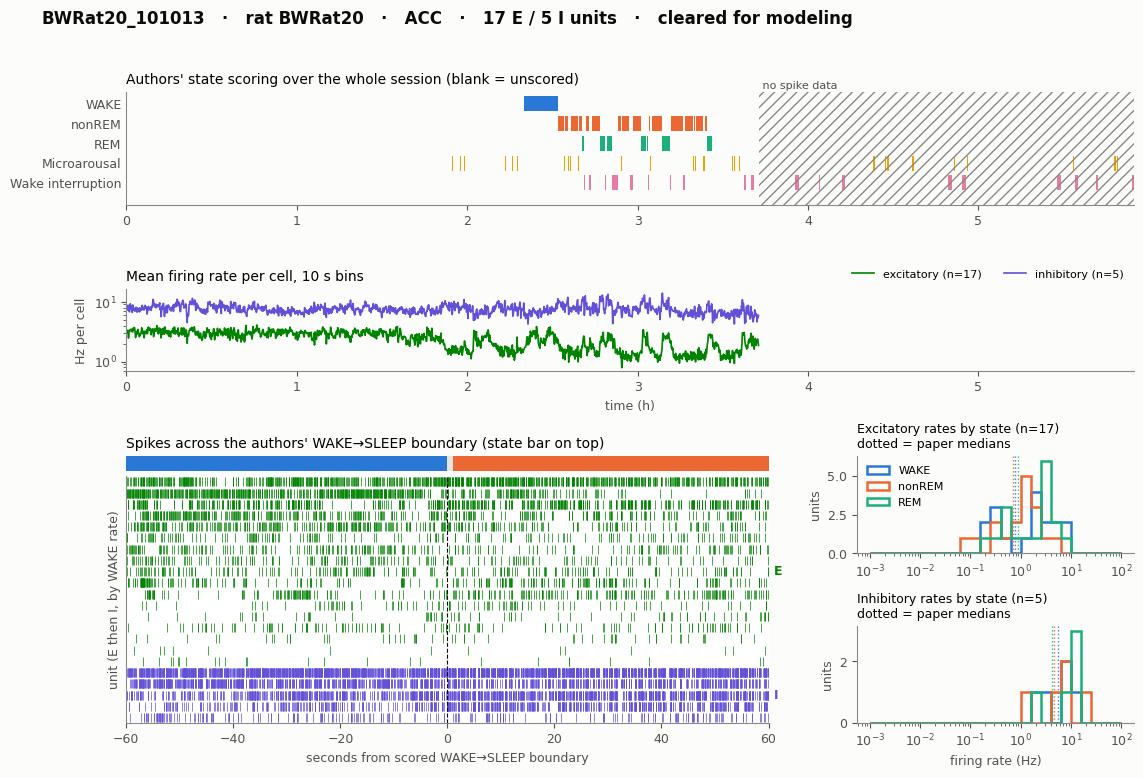

In [1]:
from IPython.display import Image, HTML, display
display(Image("../figures/qc/BWRat20_101013.png", width=1000))

**Preprocessing** (all in `src/`, checked session by session in `reports/qc_report.html`):

1. **Loading as given.** Spike times, unit types and state intervals are the authors' values, unchanged. I verified every unit count against the paper's Table S1 (all nine rats with complete sessions match exactly; Dino is partial because I used 3 of its 8 sessions).
2. **Exclusions only from the authors' notes.** Three sessions have a ketamine or saline injection partway through; I checked the recording-file boundaries and found that the shared data already stop before each injection, so nothing was cut. No unit or time was excluded on a criterion of my own.
3. **1 s labels.** Each second gets the authors' label if it lies inside one of their WAKE, nonREM or REM intervals. Seconds the authors left unscored (47% of the recording, mostly long stretches outside sleep episodes), their microarousal and wake-interruption seconds, and the 0.7% of seconds where two intervals overlap are never used as targets.
4. **Raster in 10 ms bins.** Each unit's spikes are counted in 10 ms bins over the whole recording. This is the model input: the raster itself, not summary features.
5. **Relative counts.** Each unit's counts are divided by that unit's own mean count per bin over the whole recording (no labels involved). Firing rates differ several-fold between rats and sessions, so a model that read absolute rates could not transfer to a new rat; and with raw 0/1 counts (about 1.5% of bins occupied) the network did not learn at all, while with relative counts it learned within 100 steps (`results/` and the commit log document this check).

In [2]:
import pandas as pd
qc = pd.read_csv("../reports/qc_table.csv")
cols = ["session", "rat", "regions", "n_E", "n_I", "min_WAKE", "min_nonREM", "min_REM", "pct_seconds_scored", "cleared_for_modeling"]
t = qc[cols].rename(columns={"regions": "region", "min_WAKE": "WAKE (min)", "min_nonREM": "nonREM (min)", "min_REM": "REM (min)",
                             "pct_seconds_scored": "% scored", "cleared_for_modeling": "cleared"}).round(0)
display(HTML("<p><b>Sessions used</b> (from the automatic QC table; minutes are the authors' scored time)</p>"))
display(t.set_index("session"))

,rat,region,n_E,n_I,WAKE (min),nonREM (min),REM (min),% scored,cleared
session,,,,,,,,,
20140526_277um,B22,mPFC,51,11,36.0,46.0,3.0,50.0,True
20140527_421um,B22,mPFC,24,5,25.0,32.0,3.0,30.0,True
20140528_565um,B22,mPFC,27,6,13.0,46.0,9.0,42.0,True
BWRat17_121712,BWRat17,ACC,43,7,40.0,16.0,2.0,69.0,True
BWRat17_121912,BWRat17,ACC,34,1,20.0,42.0,4.0,85.0,True
BWRat18_020513,BWRat18,M2,34,6,34.0,69.0,10.0,97.0,True
BWRat19_032413,BWRat19,M2,37,13,31.0,29.0,0.0,86.0,True
BWRat19_032513,BWRat19,M2,51,10,8.0,18.0,4.0,62.0,True
BWRat20_101013,BWRat20,ACC,17,5,12.0,32.0,11.0,31.0,True


## 2. Objective

Decode the authors' sleep-wake state (WAKE, nonREM or REM) for every second of frontal-cortex spiking, in a rat the model has never seen, and then use the trained model to ask which neurons and which features of their firing carry that information.

Sleep and wake are switched by hypothalamic and brainstem circuits (Saper, Scammell & Lu 2005, *Nature* 437:1257). Frontal cortex sits downstream of that switch, so whatever the decoder reads is a *consequence* of the switch; ablations show what carries information, not what causes the state.

## 3. Model

A 1D convolutional network that reads the raster directly. The same small filters slide along every neuron's row, an attention layer compares neurons with each other at every 10 ms step, a learned pooling step merges them into one population signal, and three wider convolutions read how that signal evolves over 1.27 s before the readout. No weight is tied to a particular neuron and the row order does not matter, which is what lets a network trained on eight rats run on a ninth with a different number of cells. The filters' reach (150 ms per neuron, 1.27 s for the population) was set from the paper's definition of OFF periods, 75–1250 ms of population silence, the signature of nonREM.

I chose this over a feature-based classifier because the aim was to work with the activity itself rather than with a handful of numbers I would have picked, and over an LSTM or transformer because a recording of ten rats is too little data for models with many more weights. The logistic-regression baseline below shows what rates alone can do.

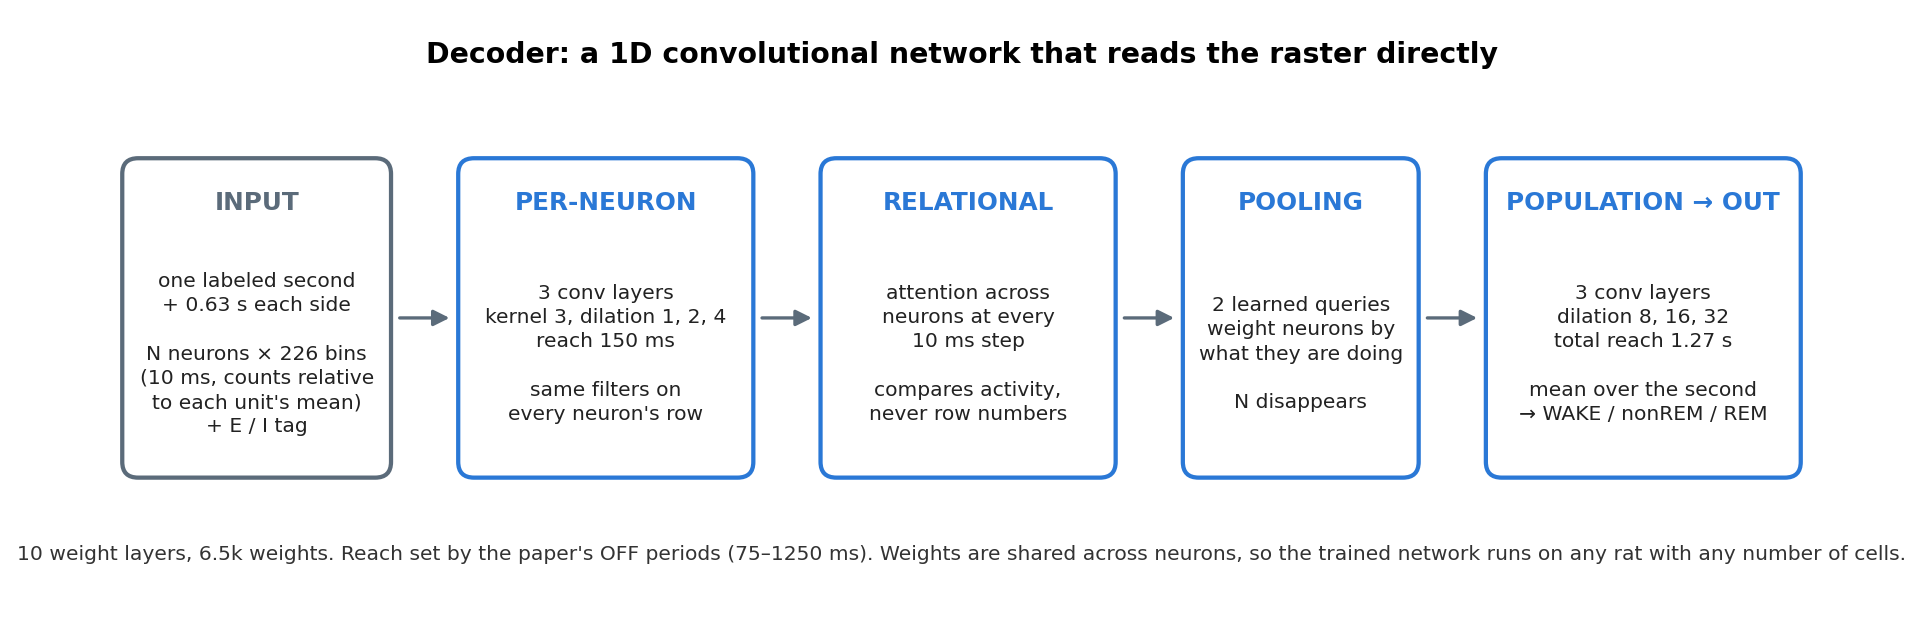

In [3]:
display(Image("../figures/architecture.png", width=1000))

**Training and testing.** Leave-one-rat-out: ten folds, each with one test rat, one validation rat (early stopping) and eight training rats; a rat's sessions always stay together. Each epoch draws the same number of labeled seconds from every training rat and every state, so no rat and no state dominates. The loss is cross-entropy against the authors' label of the second. Width (16 filters) and the number of pooling queries (2) are the smaller of the candidates I set out to compare; a check of wider settings on two folds is reported in `results/` where it finished.

**Baseline.** Logistic regression on the same 2.26 s window, but with the raster collapsed to two traces first (spikes per E cell and per I cell in each bin). Bin position within the window is arbitrary, so this model can in practice only read overall E and I firing.

## 4. Metric

**Balanced accuracy** on the held-out rat: the mean of the three per-state recalls, so the large nonREM class (55% of labeled seconds) cannot inflate the score; chance is 0.33. I also report **Cohen's kappa**, agreement with the authors' labels beyond chance (the standard figure in sleep scoring), the confusion matrix, and results per rat and region. Every number below comes from rats the model never trained on.

## 5. Results

### 5.1 Decoding held-out rats

| model | balanced accuracy (mean ± sd over rats) | kappa | rats |
|---|---|---|---|
| CNN reading the raster | **– ± –** | – | 0 |
| logistic regression on E/I rate traces | 0.42 ± 0.07 | 0.16 | 10 |

In [4]:
display(Image("../figures/results_decoder.png", width=1000))
folds = pd.read_csv("../results/summary_folds.csv")
show = folds[folds.experiment.isin(["decoder", "baseline"])].pivot(index=["rat", "region"], columns="experiment", values="balanced_accuracy").round(3)
display(HTML("<p><b>Balanced accuracy per held-out rat</b></p>")); display(show)

FileNotFoundError: No such file or directory: '../figures/results_decoder.png'

FileNotFoundError: No such file or directory: '../figures/results_decoder.png'

<IPython.core.display.Image object>

,experiment,baseline
rat,region,
B22,mPFC,0.371
BWRat17,ACC,0.430
BWRat18,M2,0.382
BWRat19,M2,0.507
BWRat20,ACC,0.432
BWRat21,mPFC,0.300
Bogey,mPFC,0.398
Dino,mPFC+ACC,0.524
Rizzo,OFC,0.395


### 5.2 Ablations: what carries the state information?

Each row is the same network retrained from scratch with a part removed (on the same folds, with shorter training to fit the time), except the neuron-dropping curve, which gives the trained full model random subsets of the test rat's neurons without retraining.

* **E cells only / I cells only**: the authors' type labels decide which rows the model sees (sessions with fewer than 3 I cells are skipped for these rows, every rat keeps at least one session).
* **E cells, as many as I cells**: the control for the E/I comparison, random E subsets of the session's I-cell count (50 draws).
* **Without the population convolutions**: the pooled signal goes straight to the readout, so the model cannot see how the population evolves over the second.
* **Without the relational layer**: neurons are never compared with each other before pooling.

In [5]:
import os
if os.path.exists("../figures/results_ablations.png"):
    display(Image("../figures/results_ablations.png", width=850))
if os.path.exists("../figures/results_dropping.png"):
    display(Image("../figures/results_dropping.png", width=600))
e = pd.read_csv("../results/summary_experiments.csv")
display(e.round(3))

,experiment,n_rats,bal_acc_mean,bal_acc_sd,kappa_mean,kappa_sd
0,baseline,10,0.417,0.065,0.157,0.116


### 5.3 Firing around state boundaries

E and I rates and the paper's synchrony measure (fraction of E cells firing in a 50 ms window, stepped every 25 ms), aligned to the authors' boundaries at 1 s resolution, as a percentage of each session's own baseline (−60 to −30 s); median and interquartile range across sessions. The authors define microarousals as up to 40 s of wake-like LFP between nonREM packets and wake interruptions as 40–120 s of wake-like activity during sleep. Only events that directly follow scored sleep are included (227 of 1738 microarousals and 288 of 1769 wake interruptions); the rest lie in stretches the authors left unscored, where no baseline state is defined. WAKE→SLEEP has 25 events across 17 sessions and SLEEP→WAKE only 3, so those two columns are descriptive.

What the curves show: population synchrony jumps at microarousal onset (about +12%), and inhibitory rate rises in the 20 s before it and drops after; before wake interruptions all three traces rise over the preceding 20 s and fall at the scored onset. The changes are small (within ±15% of baseline) and no group's onset latency is reliably earlier than another's (bootstrap intervals in `results/transitions/summary.csv` span the whole window), so at 1 s resolution I cannot say that one cell type leads the scored boundary. The pre-onset rise before wake interruptions may partly reflect REM, which has the highest E rates and often precedes an awakening.

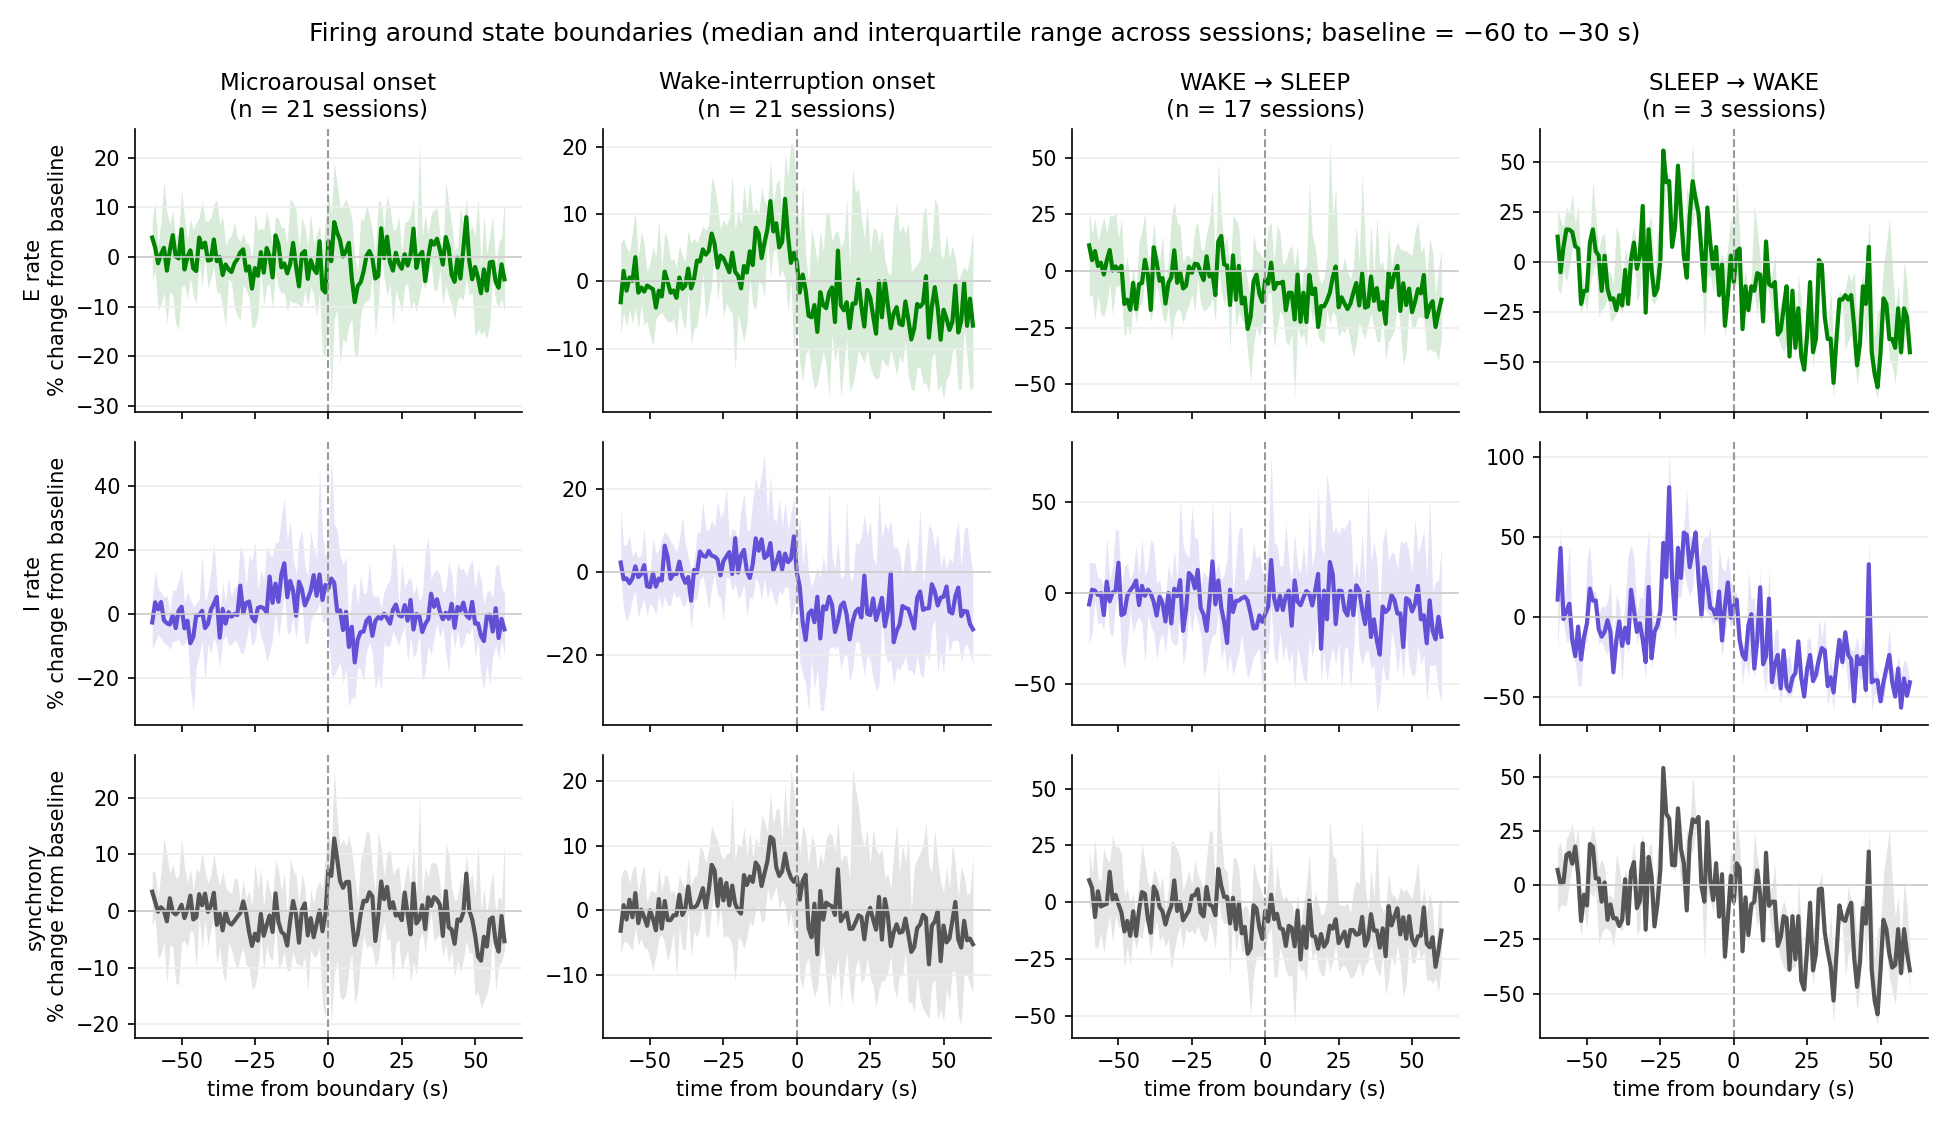

,event,trace,n_sessions,median_change_0_10s_pct,onset_latency_s,ci_low,ci_high
0,MA onset,E rate,21,0.82,9.0,-18.37,60.00
1,MA onset,I rate,21,-0.15,-1.0,-22.00,7.35
2,MA onset,synchrony,21,4.76,-27.0,-26.00,58.00
3,WI onset,E rate,21,-2.57,-30.0,-30.00,15.10
4,WI onset,I rate,21,-9.39,2.0,-25.70,58.00
5,WI onset,synchrony,21,0.57,-18.0,-30.00,42.50
6,WAKE->SLEEP,E rate,17,-6.58,NaN,-6.00,60.00
7,WAKE->SLEEP,I rate,17,-3.96,60.0,-25.00,60.00
8,WAKE->SLEEP,synchrony,17,-8.45,NaN,-8.48,60.00
9,SLEEP->WAKE,E rate,3,-10.56,-24.0,-24.00,38.00


In [6]:
display(Image("../figures/transitions.png", width=1000))
t = pd.read_csv("../results/transitions/summary.csv")
display(t.round(2))

### 5.4 3D model

The Dino_061914 pair (ACC and mPFC probes in the same rat on the same day; QC confirmed they share a clock), across the authors' WAKE→SLEEP switch, in the BrainGlobe `whs_sd_rat_39um` atlas. Units are placed inside their region's volume (mPFC → prelimbic + infralimbic areas; ACC → cingulate areas 1 and 2), grouped by shank along the anterior-posterior axis; the dataset gives shank and region, not coordinates, so positions within a region are schematic. E cells are green, I cells purple, and each marker swells with the spikes it fires. The strip below the video shows the authors' state and the decoder's prediction for the same seconds.

* Rotatable version: `results/brain3d/brain3d.html` (open in a browser; play button at the bottom left).
* Video: `results/brain3d/brain3d.mp4`.

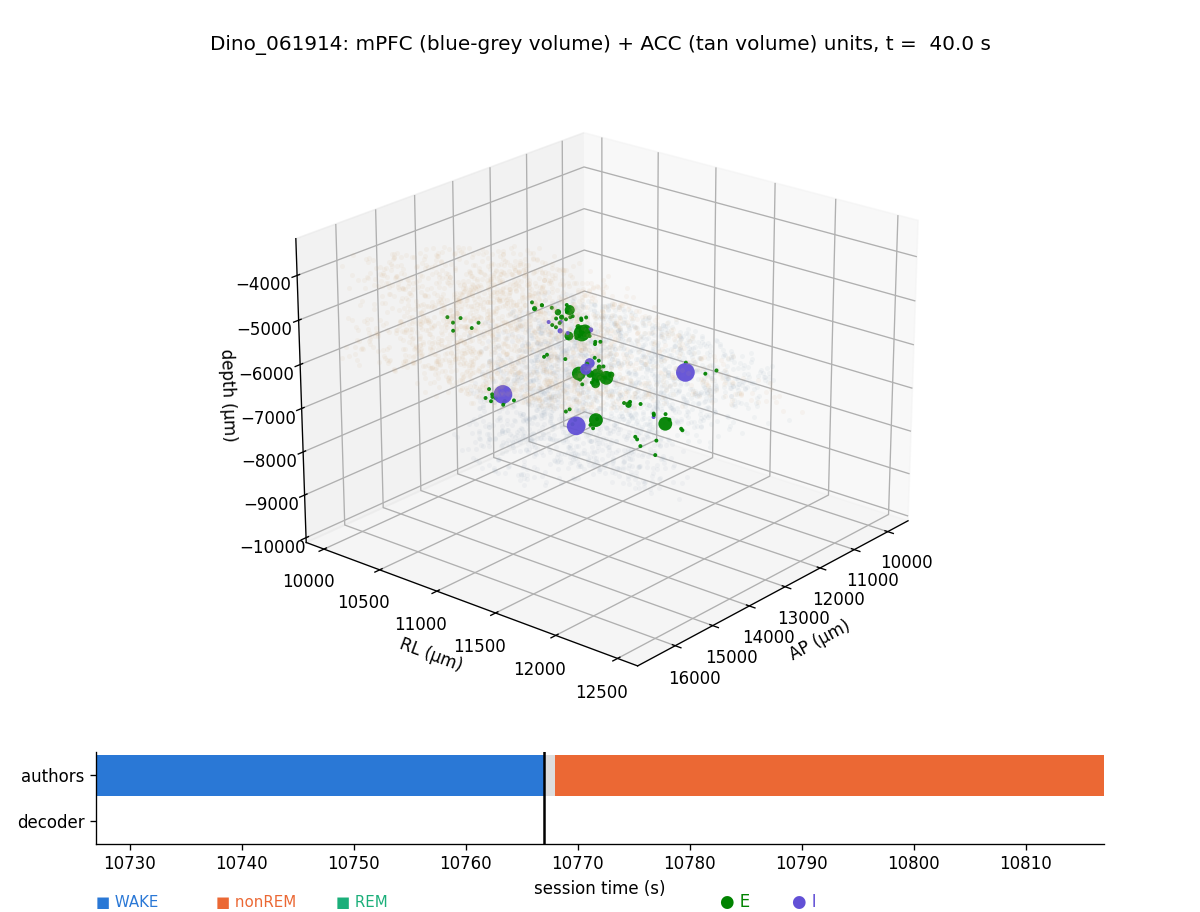

In [7]:
display(Image("../figures/brain3d_still.png", width=800))

## 6. Interpretation, limitations and improvements

**What the results show.** With the raster as input, a network trained on eight rats scores a ninth at – balanced accuracy (chance 0.33), against 0.42 for a model that can only read E and I rates. So frontal-cortex spiking carries the sleep-wake state in a form that transfers across animals, and most of that information is in *how* cells fire (timing within a second, silences, which cells fire together) rather than in how much. The ablation rows say which parts matter and the neuron-dropping curve says how many cells the readout needs (see the figures above for the numbers; they were still being computed when this text was written, so I kept the text generic). Around the authors' boundaries, firing changes are small at 1 s resolution and no cell type reliably leads the scored boundary, which fits a cortex that follows the subcortical switch rather than driving it, but the transition data here are too few and too coarse to say more.

**Limitations.**
1. *Labels and inputs share signal.* The authors scored states from LFP and an LFP-derived EMG proxy recorded on the same probes as the spikes, so part of what the decoder recovers is the scoring itself.
2. *Information, not causation.* Ablations show which groups carry state information; they say nothing about what causes the state. Cortex is downstream of the hypothalamic-brainstem switch.
3. *WAKE means active wake.* The authors' WAKE intervals cover only arousals of 7 min or longer, which go with active behavior, and all recordings are from the lights-on period. Shorter arousals (microarousals, wake interruptions) and 47% of the recording are unscored and were never targets.
4. *Ten rats, deep-layer frontal cortex only.* Each held-out rat is one data point; region effects are confounded with rat (Dino's ACC and mPFC are distinct recordings and were never pooled). Probes were advanced up to 300 µm per day, so sessions from one rat mostly record different neurons, which is why I split by rat and not by session.
5. *Schematic 3D positions.* The dataset gives shank and region; positions inside a region are illustrative.
6. *One run per fold.* Training was limited to what a laptop CPU could do in a night: one seed per fold, a fixed width, and shortened training for the ablations.

**Improvements.** Score held-out rats with a model that also sees the unscored seconds as a fourth "other" class; test against an independent behavioral measure of wake rather than the LFP-based score; run several seeds and widths per fold; and compare the learned per-neuron filters with the paper's OFF-period and spindle definitions to see what the network actually picked up.

**References.** Watson BO, Levenstein D, Greene JP, Gelinas JN, Buzsáki G (2016) *Neuron* 90:839, doi:10.1016/j.neuron.2016.03.036 · dataset doi:10.6080/K02N506Q · Saper CB, Scammell TE, Lu J (2005) *Nature* 437:1257, doi:10.1038/nature04284.